# Figure 5: STTT and VMT savings across interventions
Recreates Figure 5 from the saved intervention results in data/fig5; the San Francisco column is not included because its inputs are not available.

In [1]:
import pandas as pd
import ast
import matplotlib.pyplot as plt

In [2]:
system_dfs_list=[]
link_dfs_list=[]

In [3]:
# To use for avg/median impact heatmap (customized for toll, ce & prc, frc)
def create_metrics_toll_ce(df,filename):
    sttt_test_df=df.loc[(df["sttt_savings(hours)"]>0)]
    #vmt_test_df=df.loc[(df["vmt_savings(miles)"]>0)]
    summary_metrics = {
    "Positive STTT Savings": round(len(df.loc[df["sttt_savings(hours)"] > 0])*100/len(df["link_keys"]),2),
    "Negative STTT Savings": len(df.loc[df["sttt_savings(hours)"] < 0])*100/len(df["link_keys"]),
    "No STTT savings": round(len(df.loc[df["sttt_savings(hours)"]==0])*100/len(df["link_keys"]),2),
    "Positive VMT Savings": len(df.loc[df["vmt_savings(miles)"] > 0])*100/len(df["link_keys"]),
    "Negative VMT Savings": len(df.loc[df["vmt_savings(miles)"] < 0])*100/len(df["link_keys"]),
    "No VMT savings": len(df.loc[df["vmt_savings(miles)"]==0])*100/len(df["link_keys"]),
    "Average Percentage Impact on STTT": round((sttt_test_df["sttt_savings(hours)"] / sttt_test_df["basel_sttt (hours)"]).median() * 100 * sttt_test_df["basel_sttt (hours)"].iloc[0],4),
    "Average Percentage Impact on VMT": round((sttt_test_df["vmt_savings(miles)"] / sttt_test_df["basel_svmt (miles)"]).median() * 100 * sttt_test_df["basel_svmt (miles)"].iloc[0]*1.61,4),
    "Total STTT Savings (Hours)": round(df["sttt_savings(hours)"].sum(),2),
    "Total VMT Savings (Miles)": round(df["vmt_savings(miles)"].sum(),2),
    "Total monetized STTT Savings (Dollars)": round(df["sttt_vot_savings(dollars)"].sum(),2),
    "Total Toll Revenue (Thousand Dollars)": df["toll_revenue(thousand dollars)"].sum(),
    }
    # Assuming first link in case of multiple links intervention
    # In future iterate this metric until length of values in either columns: cap, bf_flow, bf_tt etc.
    local_link_level_metrics ={
        "percentage of cases with no travel time savings in intervened link":round(len(df.loc[(df["bf_tt_avg"].apply(lambda x: float(x[0])))*(df["bf_flow_avg"].apply(lambda x: float(x[0])))-(df["af_tt_avg"].apply(lambda x: float(x[0])))*(df["af_flow_avg"].apply(lambda x: float(x[0])))==0])*100/len(df["link_keys"]),2),
        "Percentage of cases with no traffic flow change in intervened link":round(len(df.loc[df["bf_vmt"].apply(lambda x: float(x[0]))-df["af_vmt"].apply(lambda x: float(x[0]))==0])*100/len(df["link_keys"]),2),
        "Percentage of cases with near 0 traffic flow(baseline) in intervened link(<=0.5)":round(len(df.loc[df["bf_flow_avg"].apply(lambda x: float(x[0]))<=0.5])*100/len(df["link_keys"]),2),
        "percentage of cases with positive travel time savings in intervened link":round(len(df.loc[(df["bf_tt_avg"].apply(lambda x: float(x[0])))*(df["bf_flow_avg"].apply(lambda x: float(x[0])))-(df["af_tt_avg"].apply(lambda x: float(x[0])))*(df["af_flow_avg"].apply(lambda x: float(x[0])))>0])*100/len(df["link_keys"]),2),
        "percentage of cases with negative travel time savings in intervened link":round(len(df.loc[(df["bf_tt_avg"].apply(lambda x: float(x[0])))*(df["bf_flow_avg"].apply(lambda x: float(x[0])))-(df["af_tt_avg"].apply(lambda x: float(x[0])))*(df["af_flow_avg"].apply(lambda x: float(x[0])))<0])*100/len(df["link_keys"]),2),
    }

    # Convert to DataFrame
    summary_df = pd.DataFrame(summary_metrics, index=[filename.split("_")[3]]).T
    link_level_summary_df=pd.DataFrame(local_link_level_metrics, index=[filename.split("_")[3]]).T

    return summary_df, link_level_summary_df

# To use for avg impact heatmap
# Original
def create_metrics_rc(df,filename):
    print("closure")
    #sttt_test_df=df.loc[(df["sttt_savings(hours)"]!=0)]
    #vmt_test_df=df.loc[(df["vmt_savings(miles)"]!=0)]
    summary_metrics = {
    "Positive STTT Savings": round(len(df.loc[df["sttt_savings(hours)"] > 0])*100/len(df["link_keys"]),2),
    "Negative STTT Savings": len(df.loc[df["sttt_savings(hours)"] < 0])*100/len(df["link_keys"]),
    "No STTT savings": round(len(df.loc[df["sttt_savings(hours)"]==0])*100/len(df["link_keys"]),2),
    "Positive VMT Savings": len(df.loc[df["vmt_savings(miles)"] > 0])*100/len(df["link_keys"]),
    "Negative VMT Savings": len(df.loc[df["vmt_savings(miles)"] < 0])*100/len(df["link_keys"]),
    "No VMT savings": len(df.loc[df["vmt_savings(miles)"]==0])*100/len(df["link_keys"]),
    "Average Percentage Impact on STTT": round((df["sttt_savings(hours)"] / df["basel_sttt (hours)"]).median() * 100 * df["basel_sttt (hours)"].iloc[0],4),
    "Average Percentage Impact on VMT": round((df["vmt_savings(miles)"] / df["basel_svmt (miles)"]).median() * 100 * df["basel_svmt (miles)"].iloc[0]*1.61,4),
    "Total STTT Savings (Hours)": round(df["sttt_savings(hours)"].sum(),2),
    "Total VMT Savings (Miles)": round(df["vmt_savings(miles)"].sum(),2),
    "Total monetized STTT Savings (Dollars)": round(df["sttt_vot_savings(dollars)"].sum(),2),
    "Total Toll Revenue (Thousand Dollars)": df["toll_revenue(thousand dollars)"].sum(),
    }
    # Assuming first link in case of multiple links intervention
    # In future iterate this metric until length of values in either columns: cap, bf_flow, bf_tt etc.
    local_link_level_metrics ={
        "percentage of cases with no travel time savings in intervened link":round(len(df.loc[(df["bf_tt_avg"].apply(lambda x: float(x[0])))*(df["bf_flow_avg"].apply(lambda x: float(x[0])))-(df["af_tt_avg"].apply(lambda x: float(x[0])))*(df["af_flow_avg"].apply(lambda x: float(x[0])))==0])*100/len(df["link_keys"]),2),
        "Percentage of cases with no traffic flow change in intervened link":round(len(df.loc[df["bf_vmt"].apply(lambda x: float(x[0]))-df["af_vmt"].apply(lambda x: float(x[0]))==0])*100/len(df["link_keys"]),2),
        "Percentage of cases with near 0 traffic flow(baseline) in intervened link(<=0.5)":round(len(df.loc[df["bf_flow_avg"].apply(lambda x: float(x[0]))<=0.5])*100/len(df["link_keys"]),2),
        "percentage of cases with positive travel time savings in intervened link":round(len(df.loc[(df["bf_tt_avg"].apply(lambda x: float(x[0])))*(df["bf_flow_avg"].apply(lambda x: float(x[0])))-(df["af_tt_avg"].apply(lambda x: float(x[0])))*(df["af_flow_avg"].apply(lambda x: float(x[0])))>0])*100/len(df["link_keys"]),2),
        "percentage of cases with negative travel time savings in intervened link":round(len(df.loc[(df["bf_tt_avg"].apply(lambda x: float(x[0])))*(df["bf_flow_avg"].apply(lambda x: float(x[0])))-(df["af_tt_avg"].apply(lambda x: float(x[0])))*(df["af_flow_avg"].apply(lambda x: float(x[0])))<0])*100/len(df["link_keys"]),2),
    }

    # Convert to DataFrame
    summary_df = pd.DataFrame(summary_metrics, index=[filename.split("_")[3]]).T
    link_level_summary_df=pd.DataFrame(local_link_level_metrics, index=[filename.split("_")[3]]).T

    return summary_df, link_level_summary_df

def fetch_common_link_keys(files):
    common_keys = list(set.intersection(*[set(pd.read_csv(file)['link_keys']) for file in files]))
    return common_keys


In [4]:
# To use for median impact heatmap
def create_metrics(df,filename):
    sttt_test_df=df.loc[(df["basel_sttt (hours)"]!=0) & (df["sttt_savings(hours)"]!=0)]
    vmt_test_df=df.loc[(df["basel_svmt (miles)"]!=0) & (df["vmt_savings(miles)"]!=0)]
    summary_metrics = {
    "Positive STTT Savings": round(len(df.loc[df["sttt_savings(hours)"] > 0])*100/len(df["link_keys"]),2),
    "Negative STTT Savings": len(df.loc[df["sttt_savings(hours)"] < 0])*100/len(df["link_keys"]),
    "No STTT savings": round(len(df.loc[df["sttt_savings(hours)"]==0])*100/len(df["link_keys"]),2),
    "Positive VMT Savings": len(df.loc[df["vmt_savings(miles)"] > 0])*100/len(df["link_keys"]),
    "Negative VMT Savings": len(df.loc[df["vmt_savings(miles)"] < 0])*100/len(df["link_keys"]),
    "No VMT savings": len(df.loc[df["vmt_savings(miles)"]==0])*100/len(df["link_keys"]),
    "Average Percentage Impact on STTT": round((sttt_test_df["sttt_savings(hours)"] / sttt_test_df["basel_sttt (hours)"]).median() * 100 * sttt_test_df["basel_sttt (hours)"].iloc[0],4),
    "Average Percentage Impact on VMT": round((vmt_test_df["vmt_savings(miles)"] / vmt_test_df["basel_svmt (miles)"]).median() * 100 * vmt_test_df["basel_svmt (miles)"].iloc[0]*1.61,4),
    "Total STTT Savings (Hours)": round(df["sttt_savings(hours)"].sum(),2),
    "Total VMT Savings (Miles)": round(df["vmt_savings(miles)"].sum(),2),
    "Total monetized STTT Savings (Dollars)": round(df["sttt_vot_savings(dollars)"].sum(),2),
    "Total Toll Revenue (Thousand Dollars)": df["toll_revenue(thousand dollars)"].sum(),
    }
    # Assuming first link in case of multiple links intervention
    # In future iterate this metric until length of values in either columns: cap, bf_flow, bf_tt etc.
    local_link_level_metrics ={
        "percentage of cases with no travel time savings in intervened link":round(len(df.loc[(df["bf_tt_avg"].apply(lambda x: float(x[0])))*(df["bf_flow_avg"].apply(lambda x: float(x[0])))-(df["af_tt_avg"].apply(lambda x: float(x[0])))*(df["af_flow_avg"].apply(lambda x: float(x[0])))==0])*100/len(df["link_keys"]),2),
        "Percentage of cases with no traffic flow change in intervened link":round(len(df.loc[df["bf_vmt"].apply(lambda x: float(x[0]))-df["af_vmt"].apply(lambda x: float(x[0]))==0])*100/len(df["link_keys"]),2),
        "Percentage of cases with near 0 traffic flow(baseline) in intervened link(<=0.5)":round(len(df.loc[df["bf_flow_avg"].apply(lambda x: float(x[0]))<=0.5])*100/len(df["link_keys"]),2),
        "percentage of cases with positive travel time savings in intervened link":round(len(df.loc[(df["bf_tt_avg"].apply(lambda x: float(x[0])))*(df["bf_flow_avg"].apply(lambda x: float(x[0])))-(df["af_tt_avg"].apply(lambda x: float(x[0])))*(df["af_flow_avg"].apply(lambda x: float(x[0])))>0])*100/len(df["link_keys"]),2),
        "percentage of cases with negative travel time savings in intervened link":round(len(df.loc[(df["bf_tt_avg"].apply(lambda x: float(x[0])))*(df["bf_flow_avg"].apply(lambda x: float(x[0])))-(df["af_tt_avg"].apply(lambda x: float(x[0])))*(df["af_flow_avg"].apply(lambda x: float(x[0])))<0])*100/len(df["link_keys"]),2),
    }

    # Convert to DataFrame
    summary_df = pd.DataFrame(summary_metrics, index=[filename.split("_")[3]]).T
    link_level_summary_df=pd.DataFrame(local_link_level_metrics, index=[filename.split("_")[3]]).T

    return summary_df, link_level_summary_df

def fetch_common_link_keys(files):
    common_keys = list(set.intersection(*[set(pd.read_csv(file)['link_keys']) for file in files]))
    return common_keys


Pareto_frontier_results_FRC_5b5_40epoch_2000.csv
1012
in closure
closure
Pareto_frontier_results_PRC_5b5_40epoch_2000.csv


1012
in closure
closure
Pareto_frontier_results_toll_5b5_40epoch_2000.csv
1012
Pareto_frontier_results_ce_5b5_40epoch_2000_frs.csv
1012


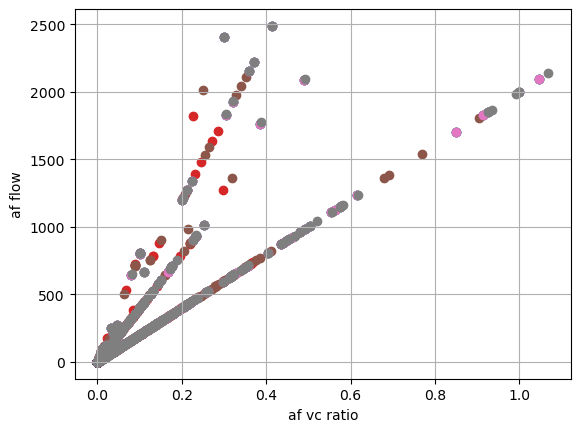

In [5]:
# Fresno 40 epochs (5by5)
file_paths = ["data/fig5/Fresno/Pareto_frontier_results_FRC_5b5_40epoch_2000.csv",
              "data/fig5/Fresno/Pareto_frontier_results_PRC_5b5_40epoch_2000.csv",
              "data/fig5/Fresno/Pareto_frontier_results_toll_5b5_40epoch_2000.csv",
              "data/fig5/Fresno/Pareto_frontier_results_ce_5b5_40epoch_2000_frs.csv",
]
complete_system_data=[]
complete_link_level_data=[]
filename_list=[]

common_link_keys=fetch_common_link_keys(file_paths)
for file in file_paths:
    filename=file.split("/")[-1]
    df = pd.read_csv(file)
    print(filename)
    # Do this for all columns with values in list
    df['bf_tt_avg'] = df['bf_tt_avg'].apply(lambda x: ast.literal_eval(x))
    df['af_tt_avg'] = df['af_tt_avg'].apply(lambda x: ast.literal_eval(x))
    df['bf_flow_avg'] = df['bf_flow_avg'].apply(lambda x: ast.literal_eval(x))
    df['af_flow_avg'] = df['af_flow_avg'].apply(lambda x: ast.literal_eval(x))
    df['bf_vmt'] = df['bf_vmt'].apply(lambda x: ast.literal_eval(x))
    df['af_vmt'] = df['af_vmt'].apply(lambda x: ast.literal_eval(x))
    df['bf_vc_avg_ratio'] = df['bf_vc_avg_ratio'].apply(lambda x: ast.literal_eval(x))
    df['af_vc_avg_ratio'] = df['af_vc_avg_ratio'].apply(lambda x: ast.literal_eval(x))
    
    # Write data filter logic here
    df=df.loc[df["bf_flow_avg"].apply(lambda x:float(x[0]))>0]
    #df=df.loc[df["bf_vc_avg_ratio"].apply(lambda x:float(x[0]))>=0.75]
    # Filter out links with no path traversing through them
    #print(len(df))
    df=df.loc[df.link_keys.isin(common_link_keys)]
    df=df.drop_duplicates(subset=["link_keys"])
    print(len(df))
    if "Pareto_frontier_results_toll" in filename:
        system_level_data,link_level_data=create_metrics_toll_ce(df, filename)
    elif "Pareto_frontier_results_ce" in filename:
        system_level_data,link_level_data=create_metrics_toll_ce(df, filename)
    else:
        print("in closure")
        system_level_data,link_level_data=create_metrics_rc(df, filename)
    complete_system_data.append(system_level_data.reset_index(drop=True))
    complete_link_level_data.append(link_level_data.reset_index(drop=True))

    plt.scatter(x=[x[0] for x in df['bf_vc_avg_ratio'].values], y=[x[0] for x in df['bf_flow_avg'].values])
    plt.xlabel('bf vc ratio')
    plt.ylabel('bf flow')
    plt.grid(True)
    #plt.show()

    plt.scatter(x=[x[0] for x in df['af_vc_avg_ratio'].values], y=[x[0] for x in df['af_flow_avg'].values])
    plt.xlabel('af vc ratio')
    plt.ylabel('af flow')
    plt.grid(True)
    #plt.show()

system_data_df=pd.concat(complete_system_data, axis=1).T
system_data_df.columns=[x for x in list(system_level_data.index)]
system_data_df["City"]="Fresno"
system_data_df["Scenario"]=system_data_df.index
system_data_df.reset_index(drop=True, inplace=True)
system_dfs_list.append(system_data_df)

link_level_data_df=pd.concat(complete_link_level_data, axis=1).T
link_level_data_df.columns=[x for x in list(link_level_data.index)]
link_level_data_df["City"]="Fresno"
link_level_data_df["Scenario"]=link_level_data_df.index
link_level_data_df.reset_index(drop=True, inplace=True)
link_dfs_list.append(link_level_data_df)

In [6]:
system_data_df

,Positive STTT Savings,Negative STTT Savings,No STTT savings,Positive VMT Savings,Negative VMT Savings,No VMT savings,Average Percentage Impact on STTT,Average Percentage Impact on VMT,Total STTT Savings (Hours),Total VMT Savings (Miles),Total monetized STTT Savings (Dollars),Total Toll Revenue (Thousand Dollars),City,Scenario
0,13.64,82.213439,4.15,7.806324,90.711462,1.482213,-48.2422,-2515.625,7228.99,1757.62,144579.84,0.000000,Fresno,FRC
1,28.75,60.276680,10.97,10.869565,84.881423,4.249012,-1.1719,-281.750,-9613.88,169582.50,-192277.58,11186.424121,Fresno,PRC
2,24.31,62.944664,12.75,8.003953,85.671937,6.324111,10.5469,-40.250,6993.42,4686.25,139868.44,13207.993427,Fresno,toll
3,35.08,4.545455,60.38,13.043478,6.225296,80.731225,2.7344,0.000,894.79,-3406.88,17895.70,17949.890149,Fresno,ce


In [7]:
link_level_data_df

,percentage of cases with no travel time savings in intervened link,Percentage of cases with no traffic flow change in intervened link,Percentage of cases with near 0 traffic flow(baseline) in intervened link(<=0.5),percentage of cases with positive travel time savings in intervened link,percentage of cases with negative travel time savings in intervened link,City,Scenario
0,0.0,0.00,2.87,100.00,0.00,Fresno,FRC
1,0.0,0.00,2.87,99.41,0.59,Fresno,PRC
2,0.0,0.00,2.87,100.00,0.00,Fresno,toll
3,42.0,27.77,2.87,39.62,18.38,Fresno,ce


San Jose
701
in closure
closure
San Jose
701
in closure
closure
San Jose


701
San Jose
701


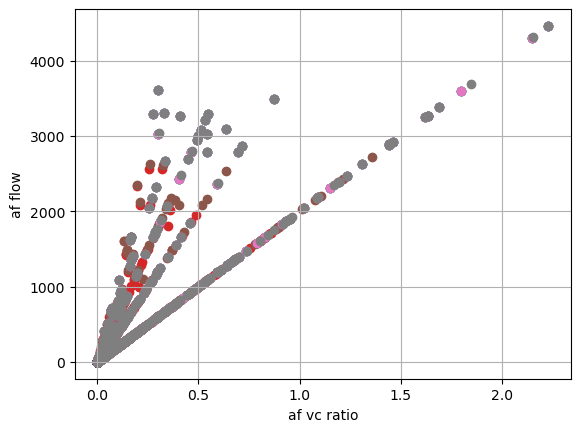

In [8]:
# Santaclara 40 epochs (5by5)
file_paths = ["data/fig5/SanJose/Pareto_frontier_results_FRC_5b5_40epoch_2000_sc.csv",
              "data/fig5/SanJose/Pareto_frontier_results_PRC_5b5_40epoch_2000_sc.csv",
              "data/fig5/SanJose/Pareto_frontier_results_toll_5b5_40epoch_2000_sc.csv",
              "data/fig5/SanJose/Pareto_frontier_results_ce_5b5_40epoch_2000_sc.csv"
]
complete_system_data=[]
complete_link_level_data=[]
filename_list=[]

common_link_keys=fetch_common_link_keys(file_paths)
for file in file_paths:
    filename=file.split("/")[-1]
    df = pd.read_csv(file)
    print("San Jose")
    # Do this for all columns with values in list
    df['bf_tt_avg'] = df['bf_tt_avg'].apply(lambda x: ast.literal_eval(x))
    df['af_tt_avg'] = df['af_tt_avg'].apply(lambda x: ast.literal_eval(x))
    df['bf_flow_avg'] = df['bf_flow_avg'].apply(lambda x: ast.literal_eval(x))
    df['af_flow_avg'] = df['af_flow_avg'].apply(lambda x: ast.literal_eval(x))
    df['bf_vmt'] = df['bf_vmt'].apply(lambda x: ast.literal_eval(x))
    df['af_vmt'] = df['af_vmt'].apply(lambda x: ast.literal_eval(x))
    df['bf_vc_avg_ratio'] = df['bf_vc_avg_ratio'].apply(lambda x: ast.literal_eval(x))
    df['af_vc_avg_ratio'] = df['af_vc_avg_ratio'].apply(lambda x: ast.literal_eval(x))
    
    # Write data filter logic here
    df=df.loc[df["bf_flow_avg"].apply(lambda x:float(x[0]))>0]
    #df=df.loc[df["bf_vc_avg_ratio"].apply(lambda x:float(x[0]))>=0.75]
    # Filter out links with no path traversing through them
    #print(len(df))
    df=df.loc[df.link_keys.isin(common_link_keys)]
    df=df.drop_duplicates(subset=["link_keys"])
    print(len(df))
    if "Pareto_frontier_results_toll" in filename:
        system_level_data,link_level_data=create_metrics_toll_ce(df, filename)
    elif "Pareto_frontier_results_ce" in filename:
        system_level_data,link_level_data=create_metrics_toll_ce(df, filename)
    else:
        print("in closure")
        system_level_data,link_level_data=create_metrics_rc(df, filename)
    complete_system_data.append(system_level_data.reset_index(drop=True))
    complete_link_level_data.append(link_level_data.reset_index(drop=True))

    plt.scatter(x=[x[0] for x in df['bf_vc_avg_ratio'].values], y=[x[0] for x in df['bf_flow_avg'].values])
    plt.xlabel('bf vc ratio')
    plt.ylabel('bf flow')
    plt.grid(True)
    #plt.show()

    plt.scatter(x=[x[0] for x in df['af_vc_avg_ratio'].values], y=[x[0] for x in df['af_flow_avg'].values])
    plt.xlabel('af vc ratio')
    plt.ylabel('af flow')
    plt.grid(True)
    #plt.show()

system_data_df=pd.concat(complete_system_data, axis=1).T
system_data_df.columns=[x for x in list(system_level_data.index)]
system_data_df["City"]="San Jose"
system_data_df["Scenario"]=system_data_df.index
system_data_df.reset_index(drop=True, inplace=True)
system_dfs_list.append(system_data_df)

link_level_data_df=pd.concat(complete_link_level_data, axis=1).T
link_level_data_df.columns=[x for x in list(link_level_data.index)]
link_level_data_df["City"]="San Jose"
link_level_data_df["Scenario"]=link_level_data_df.index
link_level_data_df.reset_index(drop=True, inplace=True)
link_dfs_list.append(link_level_data_df)

In [9]:
system_data_df

,Positive STTT Savings,Negative STTT Savings,No STTT savings,Positive VMT Savings,Negative VMT Savings,No VMT savings,Average Percentage Impact on STTT,Average Percentage Impact on VMT,Total STTT Savings (Hours),Total VMT Savings (Miles),Total monetized STTT Savings (Dollars),Total Toll Revenue (Thousand Dollars),City,Scenario
0,22.97,76.604850,0.43,16.262482,83.309558,0.427960,-796.8750,-10324.125,-200362.47,-678725.62,-4007249.38,0.000000,San Jose,FRC
1,29.39,70.328103,0.29,19.828816,77.746077,2.425107,-82.8125,-2636.375,-1102457.56,-155031.75,-22049151.25,21404.639619,San Jose,PRC
2,29.81,69.329529,0.86,20.684736,73.751783,5.563481,25176.5620,0.000,183135.00,-111395.12,3662700.00,25002.242696,San Jose,toll
3,40.23,4.992867,54.78,8.701854,10.556348,80.741797,51.5625,0.000,81579.20,-783.75,1631584.06,38688.524567,San Jose,ce


In [10]:
link_level_data_df

,percentage of cases with no travel time savings in intervened link,Percentage of cases with no traffic flow change in intervened link,Percentage of cases with near 0 traffic flow(baseline) in intervened link(<=0.5),percentage of cases with positive travel time savings in intervened link,percentage of cases with negative travel time savings in intervened link,City,Scenario
0,0.00,0.00,2.28,100.00,0.00,San Jose,FRC
1,0.29,0.00,2.28,95.15,4.56,San Jose,PRC
2,0.29,0.00,2.28,99.71,0.00,San Jose,toll
3,29.24,33.81,2.28,63.77,6.99,San Jose,ce


Pareto_frontier_results_FRC_5b5_40epoch_2000_la.csv
1032
in closure
closure
Pareto_frontier_results_PRC_5b5_40epoch_2000_la.csv
1032
in closure
closure
Pareto_frontier_results_toll_5b5_40epoch_2000_la.csv


1032
Pareto_frontier_results_ce_5b5_40epoch_2000_la.csv
1032


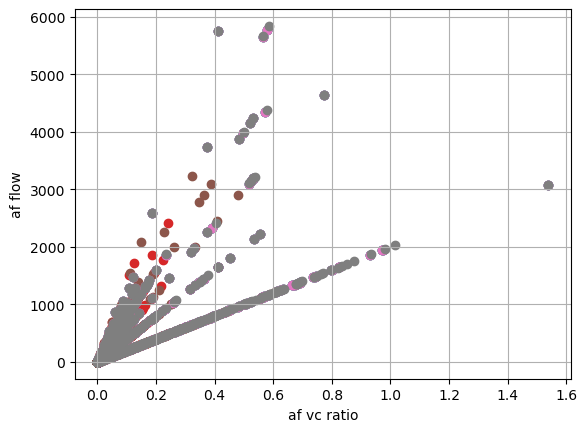

In [11]:
# LA 40 epochs (5by5)
file_paths = ["data/fig5/LosAngeles/Pareto_frontier_results_FRC_5b5_40epoch_2000_la.csv",
              "data/fig5/LosAngeles/Pareto_frontier_results_PRC_5b5_40epoch_2000_la.csv",
              "data/fig5/LosAngeles/Pareto_frontier_results_toll_5b5_40epoch_2000_la.csv",
              "data/fig5/LosAngeles/Pareto_frontier_results_ce_5b5_40epoch_2000_la.csv"
]
complete_system_data=[]
complete_link_level_data=[]
filename_list=[]

common_link_keys=fetch_common_link_keys(file_paths)
for file in file_paths:
    filename=file.split("/")[-1]
    df = pd.read_csv(file)
    print(filename)
    # Do this for all columns with values in list
    df['bf_tt_avg'] = df['bf_tt_avg'].apply(lambda x: ast.literal_eval(x))
    df['af_tt_avg'] = df['af_tt_avg'].apply(lambda x: ast.literal_eval(x))
    df['bf_flow_avg'] = df['bf_flow_avg'].apply(lambda x: ast.literal_eval(x))
    df['af_flow_avg'] = df['af_flow_avg'].apply(lambda x: ast.literal_eval(x))
    df['bf_vmt'] = df['bf_vmt'].apply(lambda x: ast.literal_eval(x))
    df['af_vmt'] = df['af_vmt'].apply(lambda x: ast.literal_eval(x))
    df['bf_vc_avg_ratio'] = df['bf_vc_avg_ratio'].apply(lambda x: ast.literal_eval(x))
    df['af_vc_avg_ratio'] = df['af_vc_avg_ratio'].apply(lambda x: ast.literal_eval(x))
    
    # Write data filter logic here
    df=df.loc[df["bf_flow_avg"].apply(lambda x:float(x[0]))>0]
    #df=df.loc[df["bf_vc_avg_ratio"].apply(lambda x:float(x[0]))>=0.75]
    # Filter out links with no path traversing through them
    #print(len(df))
    df=df.loc[df.link_keys.isin(common_link_keys)]
    df=df.drop_duplicates(subset=["link_keys"])
    print(len(df))
    if "Pareto_frontier_results_toll" in filename:
        system_level_data,link_level_data=create_metrics_toll_ce(df, filename)
    elif "Pareto_frontier_results_ce" in filename:
        system_level_data,link_level_data=create_metrics_toll_ce(df, filename)
    else:
        print("in closure")
        system_level_data,link_level_data=create_metrics_rc(df, filename)
    complete_system_data.append(system_level_data.reset_index(drop=True))
    complete_link_level_data.append(link_level_data.reset_index(drop=True))

    plt.scatter(x=[x[0] for x in df['bf_vc_avg_ratio'].values], y=[x[0] for x in df['bf_flow_avg'].values])
    plt.xlabel('bf vc ratio')
    plt.ylabel('bf flow')
    plt.grid(True)
    #plt.show()

    plt.scatter(x=[x[0] for x in df['af_vc_avg_ratio'].values], y=[x[0] for x in df['af_flow_avg'].values])
    plt.xlabel('af vc ratio')
    plt.ylabel('af flow')
    plt.grid(True)
    #plt.show()

system_data_df=pd.concat(complete_system_data, axis=1).T
system_data_df.columns=[x for x in list(system_level_data.index)]
system_data_df["City"]="Los Angeles"
system_data_df["Scenario"]=system_data_df.index
system_data_df.reset_index(drop=True, inplace=True)
system_dfs_list.append(system_data_df)

link_level_data_df=pd.concat(complete_link_level_data, axis=1).T
link_level_data_df.columns=[x for x in list(link_level_data.index)]
link_level_data_df["City"]="Los Angeles"
link_level_data_df["Scenario"]=link_level_data_df.index
link_level_data_df.reset_index(drop=True, inplace=True)
link_dfs_list.append(link_level_data_df)

In [12]:
system_data_df

,Positive STTT Savings,Negative STTT Savings,No STTT savings,Positive VMT Savings,Negative VMT Savings,No VMT savings,Average Percentage Impact on STTT,Average Percentage Impact on VMT,Total STTT Savings (Hours),Total VMT Savings (Miles),Total monetized STTT Savings (Dollars),Total Toll Revenue (Thousand Dollars),City,Scenario
0,13.76,85.465116,0.78,4.941860,93.992248,1.065891,-6023.4375,-48118.875,-902721.53,-758692.25,-18054430.62,0.000000,Los Angeles,FRC
1,35.27,62.403101,2.33,9.883721,87.015504,3.100775,-39.8438,-4689.125,-506175.08,-212172.75,-10123501.56,23891.263542,Los Angeles,PRC
2,33.53,62.693798,3.78,11.627907,81.589147,6.782946,2139.0625,-3964.625,-83129.98,-108488.25,-1662599.69,30545.913492,Los Angeles,toll
3,45.35,2.616279,52.03,10.755814,15.794574,73.449612,46.0937,0.000,17162.13,1214.50,343242.50,48566.696601,Los Angeles,ce


In [13]:
link_level_data_df

,percentage of cases with no travel time savings in intervened link,Percentage of cases with no traffic flow change in intervened link,Percentage of cases with near 0 traffic flow(baseline) in intervened link(<=0.5),percentage of cases with positive travel time savings in intervened link,percentage of cases with negative travel time savings in intervened link,City,Scenario
0,0.00,0.00,0.87,100.00,0.00,Los Angeles,FRC
1,0.00,0.00,0.87,98.16,1.84,Los Angeles,PRC
2,0.10,0.00,0.87,99.90,0.00,Los Angeles,toll
3,19.28,14.34,0.87,67.25,13.47,Los Angeles,ce


Pareto_frontier_results_FRC_5b5_40epoch_2000_sd.csv
334
in closure
closure
Pareto_frontier_results_PRC_5b5_40epoch_2000.csv
334
in closure
closure
Pareto_frontier_results_toll_5b5_40epoch_2000.csv
334
Pareto_frontier_results_ce_5b5_40epoch_2000.csv


334


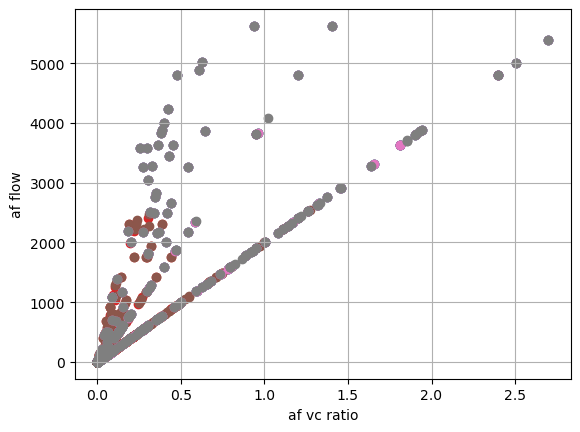

In [14]:
# Sandiego 40 epochs (b5y5)
file_paths = ["data/fig5/SanDiego/Pareto_frontier_results_FRC_5b5_40epoch_2000_sd.csv",
              "data/fig5/SanDiego/Pareto_frontier_results_PRC_5b5_40epoch_2000.csv",
              "data/fig5/SanDiego/Pareto_frontier_results_toll_5b5_40epoch_2000.csv",
              "data/fig5/SanDiego/Pareto_frontier_results_ce_5b5_40epoch_2000.csv"
]
complete_system_data=[]
complete_link_level_data=[]
filename_list=[]

common_link_keys=fetch_common_link_keys(file_paths)
for file in file_paths:
    filename=file.split("/")[-1]
    df = pd.read_csv(file)
    print(filename)
    # Do this for all columns with values in list
    df['bf_tt_avg'] = df['bf_tt_avg'].apply(lambda x: ast.literal_eval(x))
    df['af_tt_avg'] = df['af_tt_avg'].apply(lambda x: ast.literal_eval(x))
    df['bf_flow_avg'] = df['bf_flow_avg'].apply(lambda x: ast.literal_eval(x))
    df['af_flow_avg'] = df['af_flow_avg'].apply(lambda x: ast.literal_eval(x))
    df['bf_vmt'] = df['bf_vmt'].apply(lambda x: ast.literal_eval(x))
    df['af_vmt'] = df['af_vmt'].apply(lambda x: ast.literal_eval(x))
    df['bf_vc_avg_ratio'] = df['bf_vc_avg_ratio'].apply(lambda x: ast.literal_eval(x))
    df['af_vc_avg_ratio'] = df['af_vc_avg_ratio'].apply(lambda x: ast.literal_eval(x))
    
    # Write data filter logic here
    df=df.loc[df["bf_flow_avg"].apply(lambda x:float(x[0]))>0]
    #df=df.loc[df["bf_vc_avg_ratio"].apply(lambda x:float(x[0]))>=0.75]
    # Filter out links with no path traversing through them
    #print(len(df))
    df=df.loc[df.link_keys.isin(common_link_keys)]
    df=df.drop_duplicates(subset=["link_keys"])
    print(len(df))
    if "Pareto_frontier_results_toll" in filename:
        system_level_data,link_level_data=create_metrics_toll_ce(df, filename)
    elif "Pareto_frontier_results_ce" in filename:
        system_level_data,link_level_data=create_metrics_toll_ce(df, filename)
    else:
        print("in closure")
        system_level_data,link_level_data=create_metrics_rc(df, filename)
    complete_system_data.append(system_level_data.reset_index(drop=True))
    complete_link_level_data.append(link_level_data.reset_index(drop=True))

    plt.scatter(x=[x[0] for x in df['bf_vc_avg_ratio'].values], y=[x[0] for x in df['bf_flow_avg'].values])
    plt.xlabel('bf vc ratio')
    plt.ylabel('bf flow')
    plt.grid(True)
    #plt.show()

    plt.scatter(x=[x[0] for x in df['af_vc_avg_ratio'].values], y=[x[0] for x in df['af_flow_avg'].values])
    plt.xlabel('af vc ratio')
    plt.ylabel('af flow')
    plt.grid(True)
    #plt.show()

system_data_df=pd.concat(complete_system_data, axis=1).T
system_data_df.columns=[x for x in list(system_level_data.index)]
system_data_df["City"]="San Diego"
system_data_df["Scenario"]=system_data_df.index
system_data_df.reset_index(drop=True, inplace=True)
system_dfs_list.append(system_data_df)

link_level_data_df=pd.concat(complete_link_level_data, axis=1).T
link_level_data_df.columns=[x for x in list(link_level_data.index)]
link_level_data_df["City"]="San Diego"
link_level_data_df["Scenario"]=link_level_data_df.index
link_level_data_df.reset_index(drop=True, inplace=True)
link_dfs_list.append(link_level_data_df)

In [15]:
system_data_df

,Positive STTT Savings,Negative STTT Savings,No STTT savings,Positive VMT Savings,Negative VMT Savings,No VMT savings,Average Percentage Impact on STTT,Average Percentage Impact on VMT,Total STTT Savings (Hours),Total VMT Savings (Miles),Total monetized STTT Savings (Dollars),Total Toll Revenue (Thousand Dollars),City,Scenario
0,14.37,82.634731,2.99,16.467066,81.736527,1.796407,-4353.125,-20688.500,-8961249.20,-1337192.25,-1.792250e+08,0.000000,San Diego,FRC
1,24.85,67.365269,7.78,17.065868,79.940120,2.994012,-140.625,-5212.375,-10768748.31,-730078.25,-2.153750e+08,13743.558645,San Diego,PRC
2,26.05,65.568862,8.38,17.664671,78.143713,4.191617,19956.250,-9780.750,-4154032.20,-608706.75,-8.308064e+07,17288.004543,San Diego,toll
3,52.99,3.293413,43.71,18.562874,19.161677,62.275449,1575.000,0.000,171970.63,-84.25,3.439412e+06,40258.532848,San Diego,ce


In [16]:
link_level_data_df

,percentage of cases with no travel time savings in intervened link,Percentage of cases with no traffic flow change in intervened link,Percentage of cases with near 0 traffic flow(baseline) in intervened link(<=0.5),percentage of cases with positive travel time savings in intervened link,percentage of cases with negative travel time savings in intervened link,City,Scenario
0,0.00,0.00,5.09,100.00,0.00,San Diego,FRC
1,0.00,0.00,5.09,93.11,6.89,San Diego,PRC
2,0.00,0.00,5.09,100.00,0.00,San Diego,toll
3,23.35,56.29,5.09,72.46,4.19,San Diego,ce


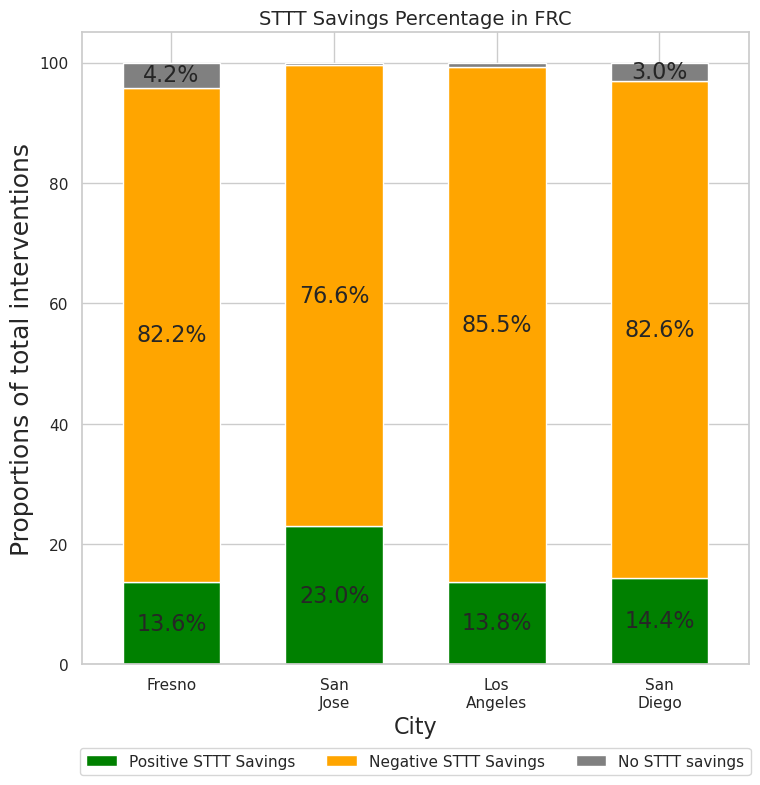

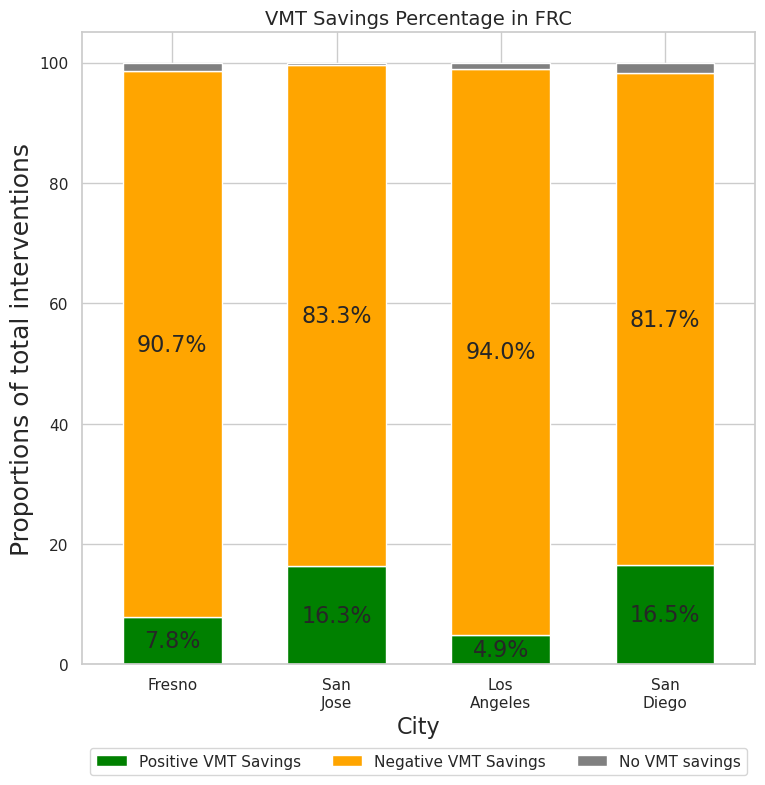

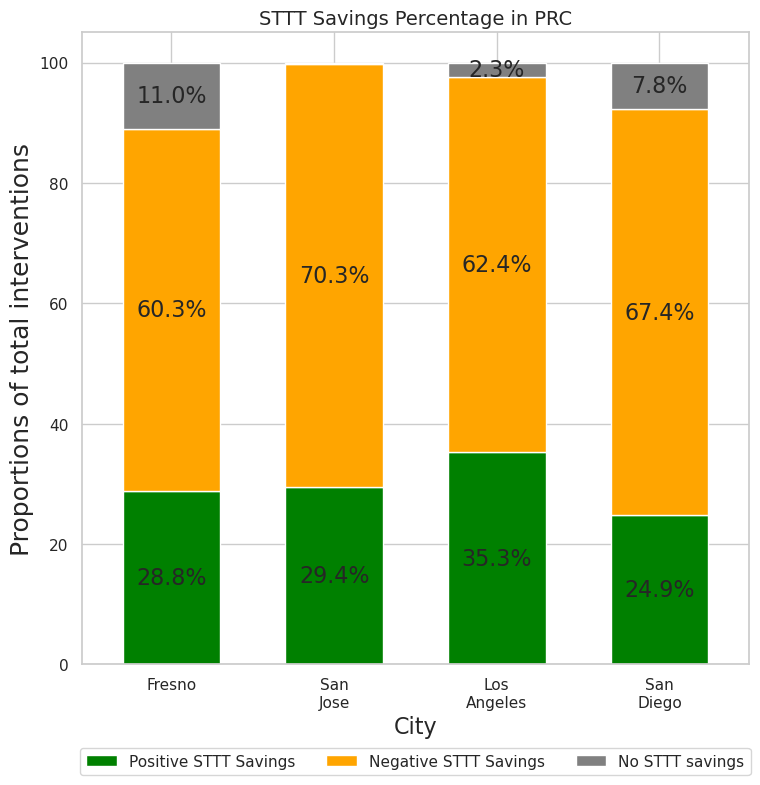

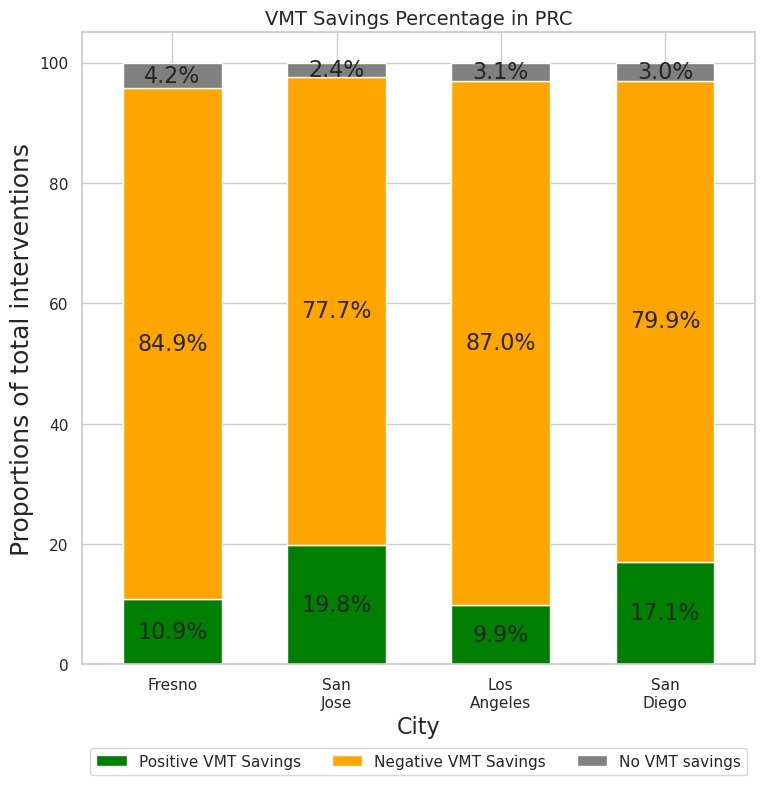

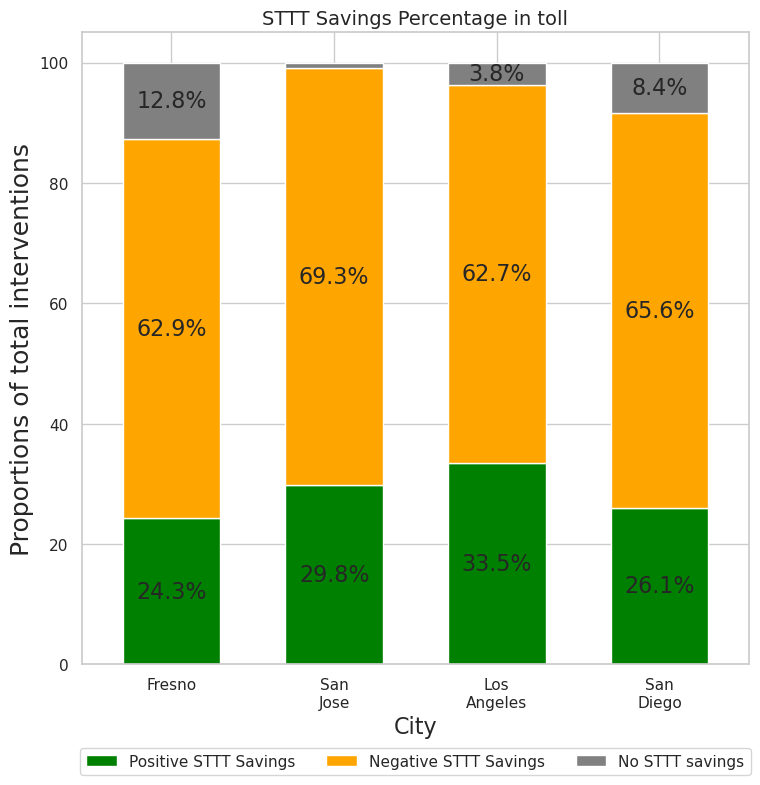

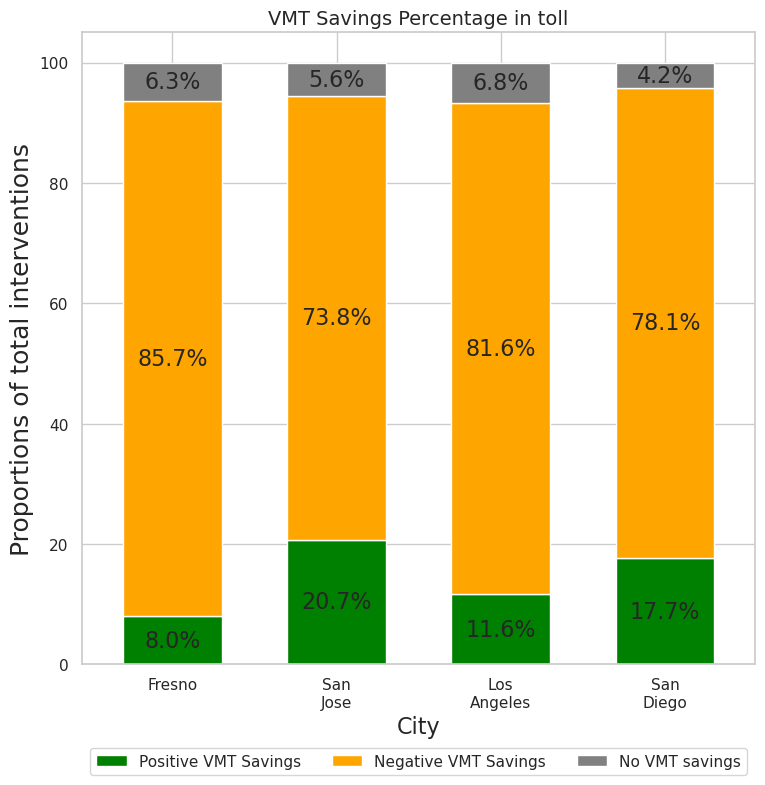

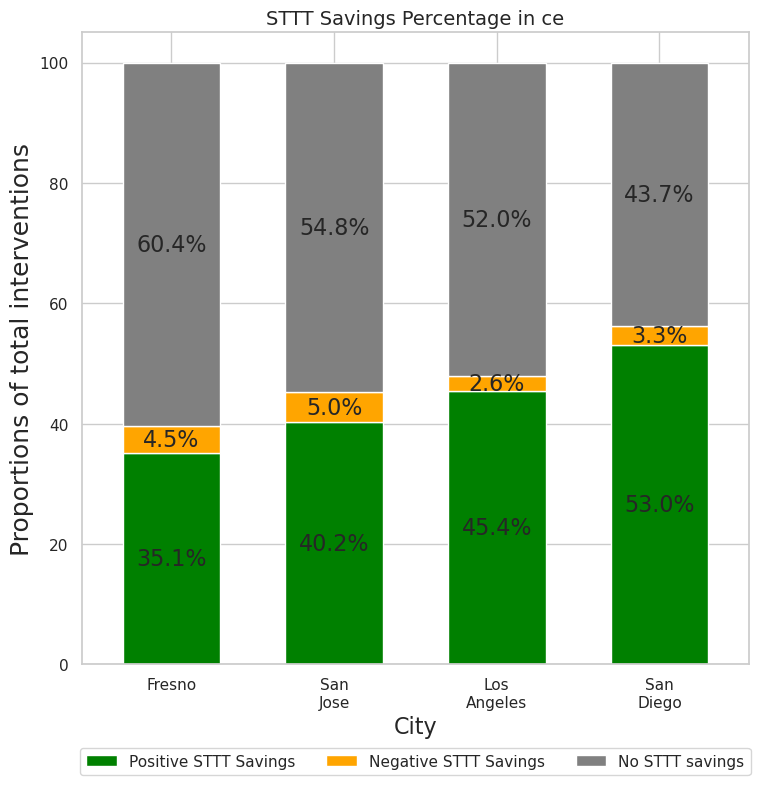

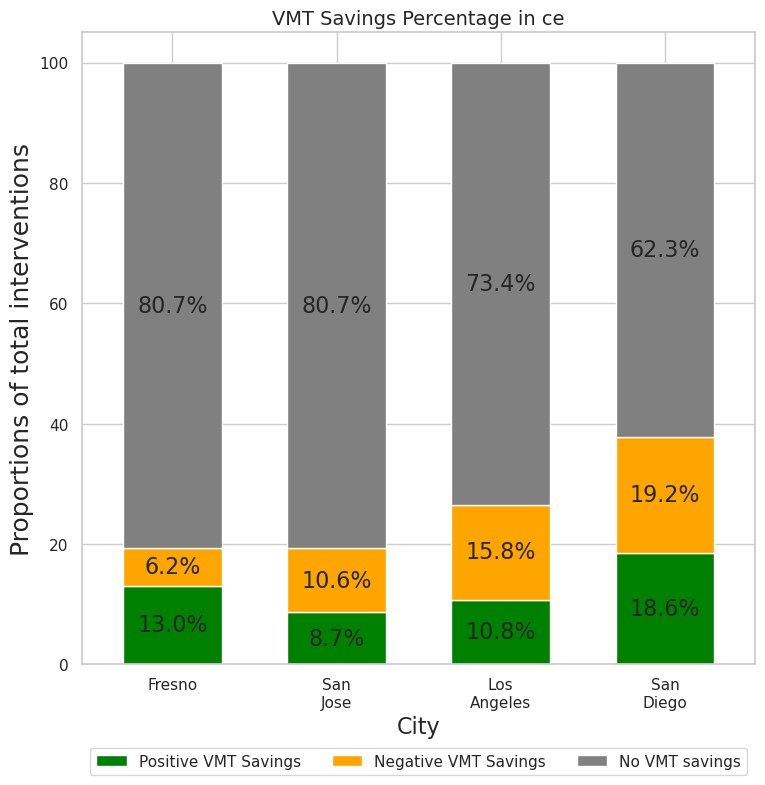

In [17]:
# New
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

os.makedirs('outputs', exist_ok=True)

df = pd.concat(system_dfs_list)
sns.set(style='whitegrid')

custom_colors = ['Green', 'Orange', 'Gray']

# Break two-word city names into two lines
df['City'] = df['City'].str.replace(' ', '\n')

for scenario in df.Scenario.unique():
    scn_df = df[df.Scenario == scenario]

    # ------------------ 1. STTT Savings ------------------
    sttt_stack = scn_df[['Positive STTT Savings', 
                         'Negative STTT Savings', 
                         'No STTT savings']]
    sttt_stack.index = scn_df['City']

    ax = sttt_stack.plot(kind='bar', stacked=True, width=0.6, figsize=(8, 8), color=custom_colors)

    plt.title(f'STTT Savings Percentage in {scenario}', fontsize=14)
    plt.xlabel('')
    plt.ylabel('Proportions of total interventions', fontsize=18)
    plt.xlabel('City', fontsize=16)
    plt.legend(
        bbox_to_anchor=(0.5, -0.12),
        loc='upper center',
        frameon=True,
        ncol=len(sttt_stack.columns)
    )
    plt.xticks(rotation=0)

    for container in ax.containers:
        labels = [f'{v.get_height():.1f}%' if v.get_height() >= 2 else '' for v in container]
        ax.bar_label(container, labels=labels, fmt='%.1f', label_type='center', fontsize=16)

    plt.tight_layout()
    plt.savefig(f'outputs/STTT Savings in {scenario}.png')
    plt.show()

    # ------------------ 2. VMT Savings ------------------
    vmt_stack = scn_df[['Positive VMT Savings', 
                        'Negative VMT Savings', 
                        'No VMT savings']]
    vmt_stack.index = scn_df['City']

    ax = vmt_stack.plot(kind='bar', stacked=True, width=0.6, figsize=(8, 8), color=custom_colors)

    plt.title(f'VMT Savings Percentage in {scenario}', fontsize=14)
    plt.ylabel('Proportions of total interventions', fontsize=18)
    plt.xlabel('City', fontsize=16)
    plt.legend(
        bbox_to_anchor=(0.5, -0.12),
        loc='upper center',
        frameon=True,
        ncol=len(vmt_stack.columns)
    )
    plt.xticks(rotation=0)

    for container in ax.containers:
        labels = [f'{v.get_height():.1f}%' if v.get_height() >= 2 else '' for v in container]
        ax.bar_label(container, labels=labels, fmt='%.1f', label_type='center', fontsize=16)

    plt.tight_layout()
    plt.savefig(f'outputs/VMT Savings in {scenario}.png')
    plt.show()

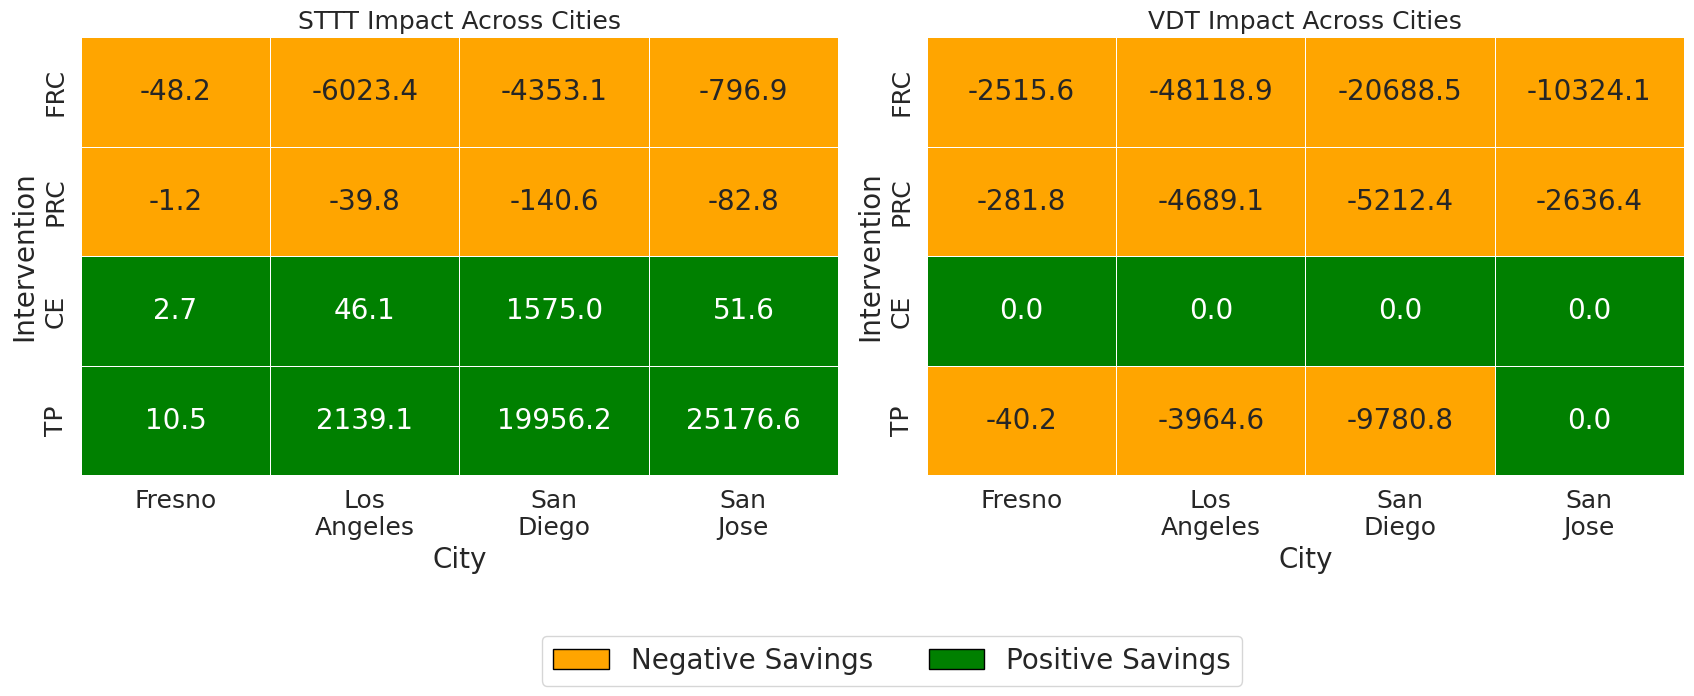

In [18]:
# for avg impact heatmap
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
import numpy as np
from matplotlib.patches import Patch

# Combine all system DataFrames
df = pd.concat(system_dfs_list)

df['City'] = df['City'].str.replace(' ', '\n')

# Define two discrete colors
colors = ["orange", "green"]
cmap = ListedColormap(colors)

# Create a common legend
legend_elements = [
    Patch(facecolor='Orange', edgecolor='black', label='Negative Savings'),
    Patch(facecolor='green', edgecolor='black', label='Positive Savings')
]

# Prepare pivot tables
sttt_df = df[['Scenario', 'City', 'Average Percentage Impact on STTT']]
sttt_pivot = sttt_df.pivot(index='Scenario', columns='City', values='Average Percentage Impact on STTT')
sttt_clean = sttt_pivot.replace([np.inf, -np.inf], np.nan).fillna(0)

vmt_df = df[['Scenario', 'City', 'Average Percentage Impact on VMT']]
vmt_pivot = vmt_df.pivot(index='Scenario', columns='City', values='Average Percentage Impact on VMT')
vmt_clean = vmt_pivot.replace([np.inf, -np.inf], np.nan).fillna(0)

# Define shared bounds and norm for both heatmaps
global_min = min(sttt_clean.min().min(), vmt_clean.min().min())
global_max = max(sttt_clean.max().max(), vmt_clean.max().max())
bounds = [global_min, -0.00001, global_max]
norm = BoundaryNorm(bounds, cmap.N)

# Create 1x2 subplot
fig, axs = plt.subplots(1, 2, figsize=(18, 6))

# --- STTT Heatmap ---
sns.heatmap(
    sttt_clean,
    annot=True,
    cmap=cmap,
    norm=norm,
    linewidths=0.5,
    fmt=".1f",
    annot_kws={"size": 20},
    cbar=False,
    ax=axs[0],
    yticklabels=True
)
axs[0].set_xlabel("City", fontsize=20)
axs[0].set_ylabel("Intervention", fontsize=20)
axs[0].set_title("STTT Impact Across Cities", fontsize=18)
axs[0].tick_params(axis='x', labelsize=18)
axs[0].tick_params(axis="y", labelsize=18)
axs[0].set_yticks(ticks=[0.5, 1.5, 2.5, 3.5], labels=['FRC', 'PRC', 'CE', 'TP'])

# --- VMT Heatmap ---
sns.heatmap(
    vmt_clean,
    annot=True,
    cmap=cmap,
    norm=norm,
    linewidths=0.5,
    fmt=".1f",
    annot_kws={"size": 20},
    cbar=False,
    ax=axs[1],
    yticklabels=True
)
axs[1].set_title("VDT Impact Across Cities", fontsize=18)
axs[1].set_xlabel("City", fontsize=20)
axs[1].set_ylabel("Intervention", fontsize=20)
axs[1].tick_params(axis='x', labelsize=18)
axs[1].tick_params(axis='y', labelsize=18)  # Increase y-axis labels for VMT
axs[1].set_yticks(ticks=[0.5, 1.5, 2.5, 3.5], labels=['FRC', 'PRC', 'CE', 'TP'])

# Add common legend to the right
fig.legend(
    handles=legend_elements,
    bbox_to_anchor=(0.5, -0.05),
    ncol=len(vmt_clean.columns),
    fontsize=20,
    loc='upper center',
    frameon=True
)
plt.tight_layout(rect=[0, 0, 0.95, 1])  # Leave space for legend
plt.savefig("outputs/STTT VMT Impact Across Multiple Cities.png")
plt.show()
